# **Fase de Análisis Exploratorio de Datos - Deri Solutions**


In [26]:
#Librerias
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os
import io

# Carga del archivo

In [27]:
subido = files.upload()                   # Seleccionar archivo
nombre_archivo = list(subido.keys())[0]   # Obtener el nombre
datos_base = pd.read_csv(nombre_archivo, encoding='latin1')  # Leer el CSV

datos_ordenes = pd.DataFrame(datos_base) # DataFrame
datos_ordenes.head(5)

Saving datos_ordenes_limpios.csv to datos_ordenes_limpios (2).csv


,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,sales,quantity,discount,profit,shipping_cost,order_priority,year,process_time,limit_day,diference
0,AG-2011-2040,01/01/2011,06/01/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,408,2,0.0,106.140,35.46,Medium,2011,5,4,1
1,HU-2011-1220,01/01/2011,05/01/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,66,4,0.0,29.640,8.17,High,2011,4,2,2
2,IT-2011-3647632,01/01/2011,05/01/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,45,3,0.5,-26.055,4.82,High,2011,4,2,2
3,CA-2011-1510,02/01/2011,06/01/2011,Standard Class,Magdelene Morse,Consumer,Ontario,Canada,Canada,Canada,...,314,1,0.0,3.120,24.10,Medium,2011,4,4,0
4,IN-2011-79397,03/01/2011,03/01/2011,Same Day,Kean Nguyen,Corporate,New South Wales,Australia,APAC,Oceania,...,276,1,0.1,110.412,125.32,Critical,2011,0,0,0


#**Fase 1**

In [28]:
# Resumen en consola de los KPIs
# Copia del DataFrame a partir de los datos cargados, para evitar modificar el original
df = datos_ordenes.copy()

# Creacipon de columnas adicionales para el calculo del KPIs
df["on_time"] = df["process_time"] <= df["limit_day"]
df["late_shipment"] = ~df["on_time"]

#Resumen de KPIs
print("Kpis resumidos")
print(f"Total de Pedidos: {len(df):,}")
print(f"Tiempo Promedio de Procesamiento: {df['process_time'].mean():.2f} días")
print(f"Mediana de Tiempo de Procesamiento: {df['process_time'].median()} días")
print(f"Tasa de Cumplimiento de SLA (On-Time): {df['on_time'].mean() * 100:.2f}%")
print(
    f"Tasa de Retraso Crítico (Late Shipments): {df['late_shipment'].mean() * 100:.2f}%"
)

Kpis resumidos
Total de Pedidos: 46,574
Tiempo Promedio de Procesamiento: 4.00 días
Mediana de Tiempo de Procesamiento: 4.0 días
Tasa de Cumplimiento de SLA (On-Time): 39.08%
Tasa de Retraso Crítico (Late Shipments): 60.92%


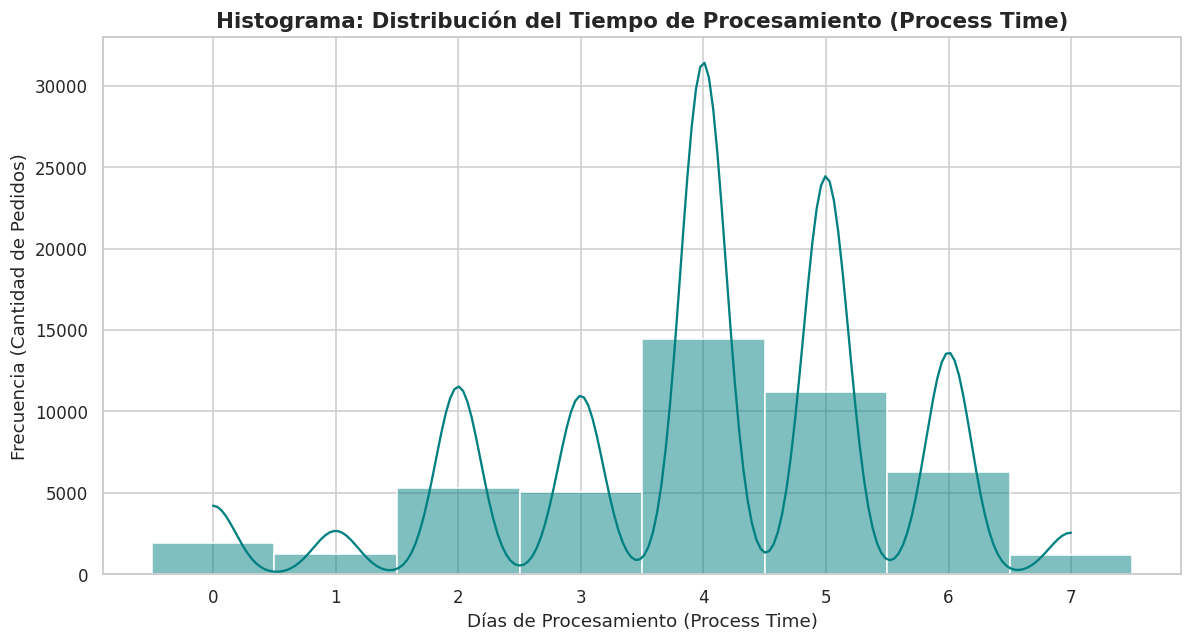

In [29]:
# Configuración del estilo visual
sns.set_theme(style="whitegrid")

# Generar el Histograma de Tiempos de Procesamiento
plt.figure(figsize=(11, 6))
sns.histplot(
    data=df,
    x="process_time",
    bins=range(int(df["process_time"].min()), int(df["process_time"].max()) + 2),
    discrete=True,
    kde=True,
    color="teal",
)

# Configuracion de titulos de la grafica y ejes
plt.title(
    "Histograma: Distribución del Tiempo de Procesamiento (Process Time)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Días de Procesamiento (Process Time)", fontsize=12)
plt.ylabel("Frecuencia (Cantidad de Pedidos)", fontsize=12)
plt.tight_layout()

# Se muestra la grafica
plt.show()


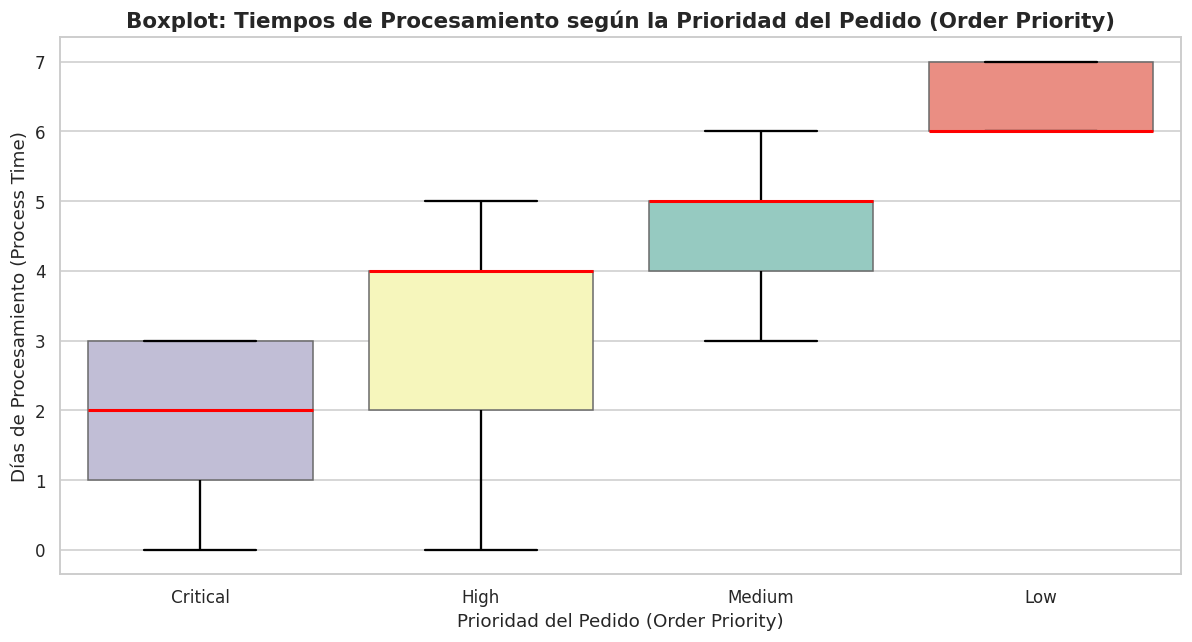

In [30]:
# Creación del Boxplot por Prioridad de Pedido
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="order_priority",
    y="process_time",
    hue="order_priority",
    palette="Set3",
    legend=False,
    order=[
        "Critical",
        "High",
        "Medium",
        "Low",
    ],
    medianprops={"color": "red", "linewidth": 2},
    whiskerprops={"color": "black", "linewidth": 1.5},
    capprops={"color": "black", "linewidth": 1.5}
)

#Configuracion del titulo y ejes
plt.title(
    "Boxplot: Tiempos de Procesamiento según la Prioridad del Pedido (Order Priority)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Prioridad del Pedido (Order Priority)", fontsize=12)
plt.ylabel("Días de Procesamiento (Process Time)", fontsize=12)
plt.tight_layout()

# Se muestra la imagen
plt.show()

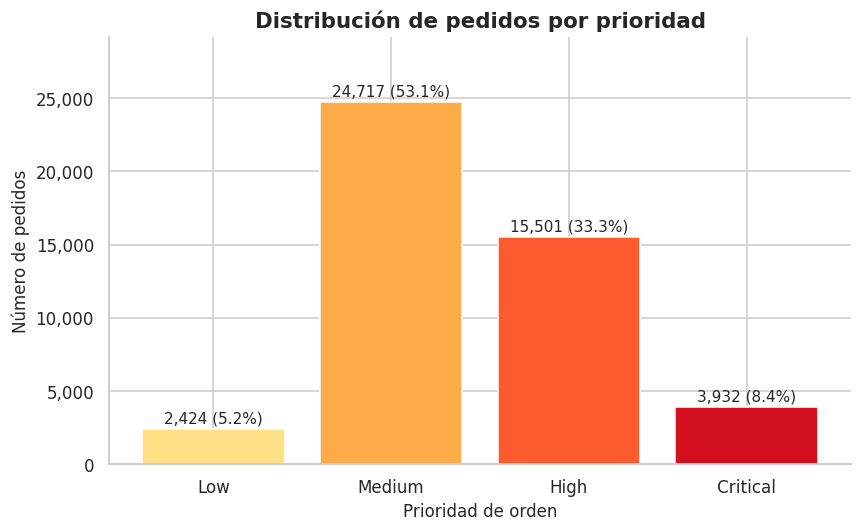

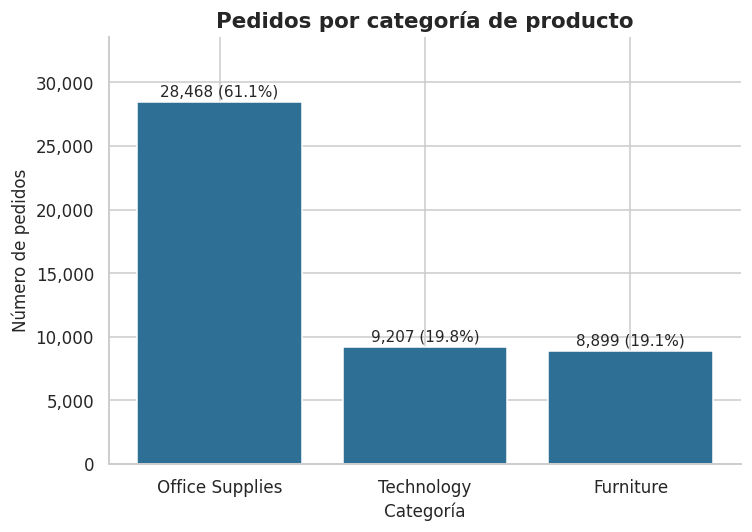

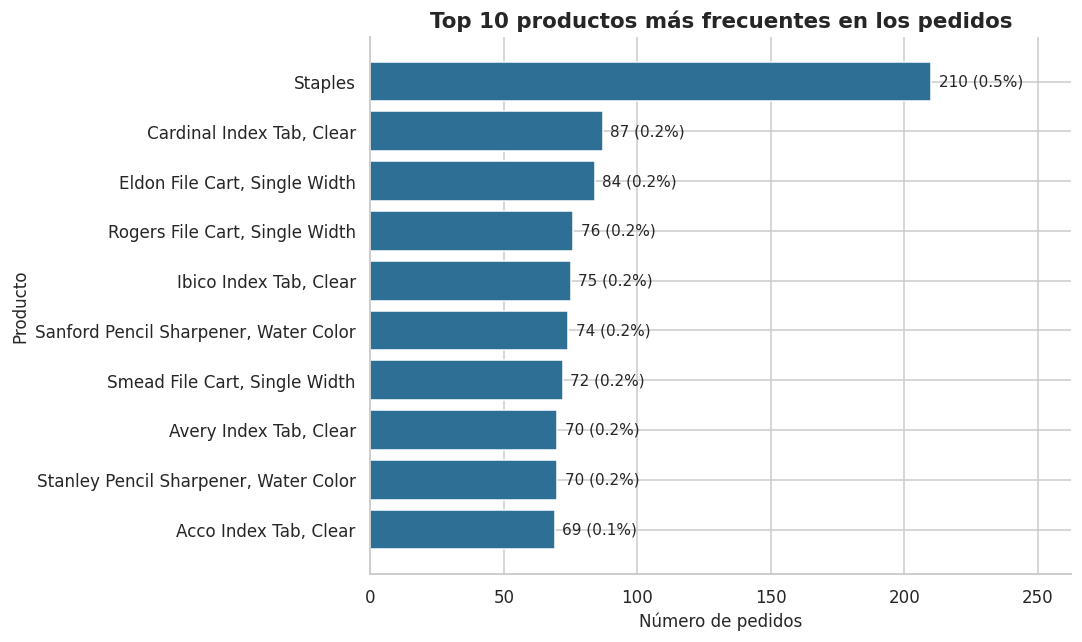

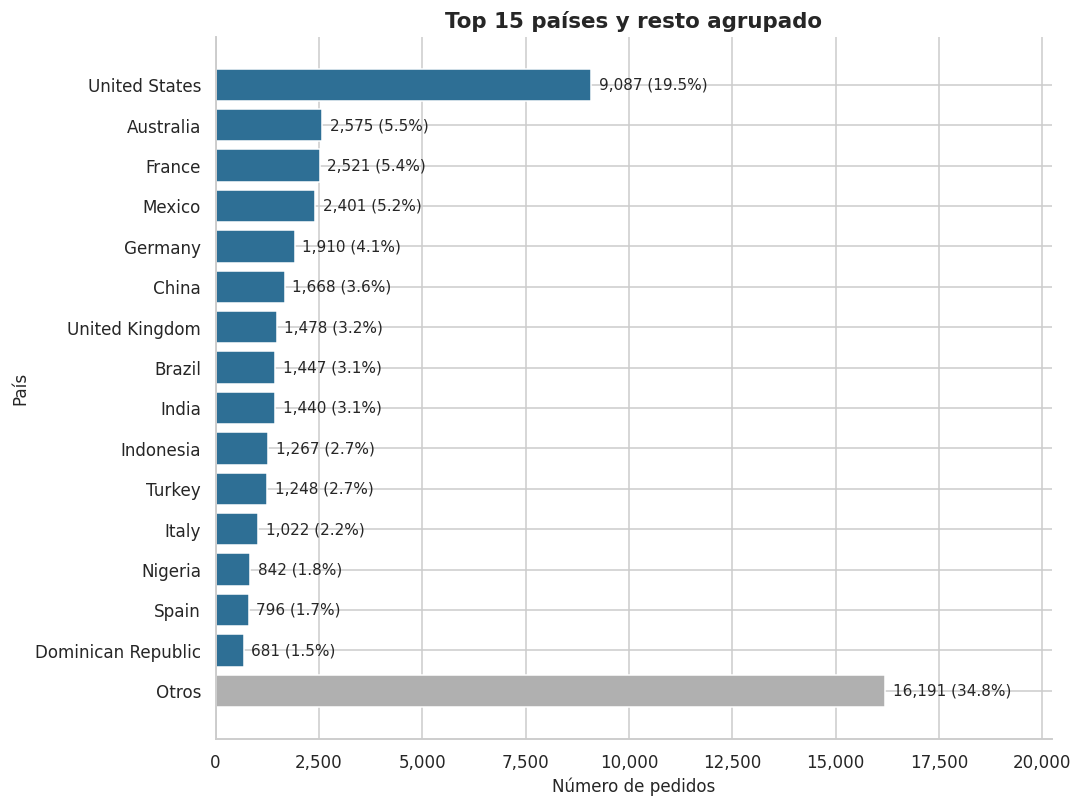

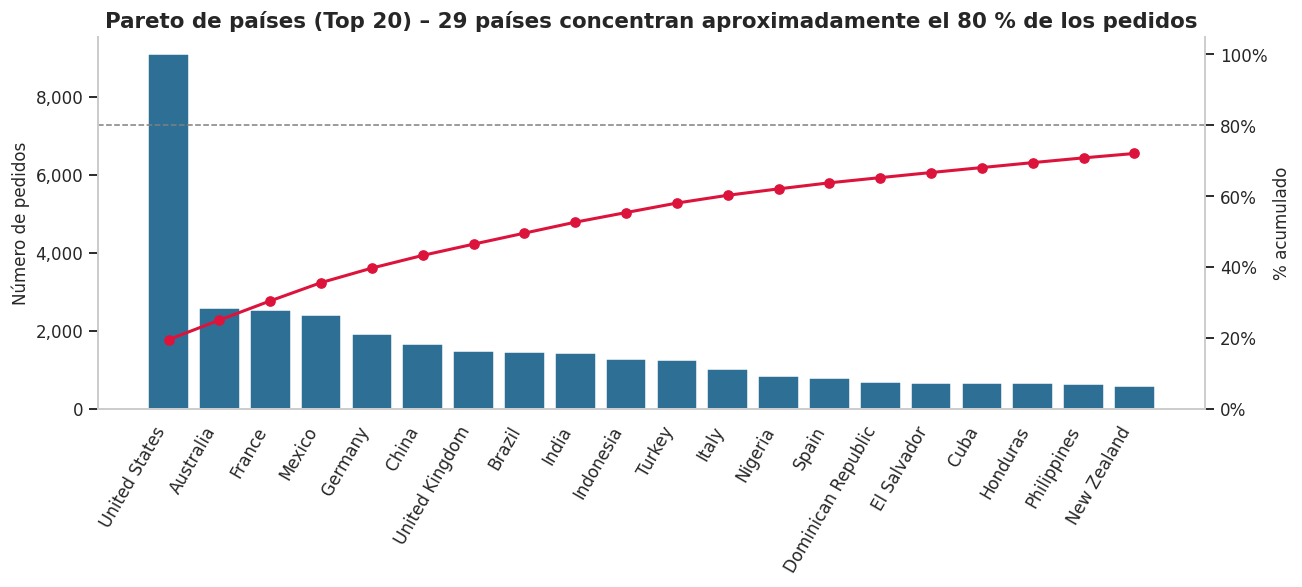

Países necesarios para llegar al 80 %: 29 de 146

=== Prioridad ===
                frecuencia  porcentaje  acumulado_%
order_priority                                     
Low                   2424        5.20         5.20
Medium               24717       53.07        58.28
High                 15501       33.28        91.56
Critical              3932        8.44       100.00

=== Categoría ===
                 frecuencia  porcentaje  acumulado_%
category                                            
Office Supplies       28468       61.12        61.12
Technology             9207       19.77        80.89
Furniture              8899       19.11       100.00

=== Top 10 productos ===
                                       frecuencia  porcentaje  acumulado_%
product_name                                                              
Staples                                       210        0.45         0.45
Cardinal Index Tab, Clear                      87        0.19         0.64
Eldon File

In [31]:
# Configuración visual
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Asegurar que df contenga los datos de las órdenes cargadas al inicio de manera segura
if 'datos_ordenes' in globals():
    df = datos_ordenes.copy()
elif 'df' in globals():
    # Si 'datos_ordenes' no está pero 'df' existe, usamos una copia del df actual
    df = df.copy()
else:
    raise NameError("No se encontraron datos cargados en 'datos_ordenes' ni en 'df'. Por favor vuelve a ejecutar la celda de carga de archivo.")

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "figure.max_open_warning": 0,
})

# Configuraciones y variables
guardar_archivos = False
carpeta_figuras = "."
color_base = "#2E6F95"
orden_prioridad = ["Low", "Medium", "High", "Critical"]
pal_prioridad = dict(zip(orden_prioridad, sns.color_palette("YlOrRd", 4)))

# Funcion para guardar las figuras en png cuando guardar_archivos=True
def guardar(fig, nombre):
    if guardar_archivos:
        os.makedirs(carpeta_figuras, exist_ok=True)
        fig.savefig(
            os.path.join(carpeta_figuras, f"{nombre}.png"),
            bbox_inches="tight",
            dpi=200,
        )

# Funcion para el calculo de frecuencia absoluta, porcentaje y porcentaje acumulado
def tabla_frecuencias(serie, orden=None):
    conteo = serie.value_counts()
    if orden is not None:
        conteo = conteo.reindex(orden).fillna(0).astype(int)

    tabla = pd.DataFrame({"frecuencia": conteo})
    tabla["porcentaje"] = tabla["frecuencia"] / tabla["frecuencia"].sum() * 100
    tabla["acumulado_%"] = tabla["porcentaje"].cumsum()
    return tabla

# Funcion para agregar etiquetas de conteo y porcentaje en cada barra del grafico
def etiquetar_barras(ax, tabla, horizontal=False, fontsize=10):
    for barra, (n, p) in zip(
        ax.patches,
        zip(tabla["frecuencia"], tabla["porcentaje"]),
    ):
        texto = f"{n:,.0f} ({p:.1f}%)"
        # Si la grafica es horizontal coloca el texto encima de la barra
        if horizontal:
            ax.annotate(
                texto,
                (barra.get_width(), barra.get_y() + barra.get_height() / 2),
                xytext=(5, 0),
                textcoords="offset points",
                va="center",
                fontsize=fontsize,
            )
        # Si no es horizontal coloca el texto al final de la barra
        else:
            ax.annotate(
                texto,
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                fontsize=fontsize,
            )

# Funcion para crear graficos de frecuencia con conteo y porcentaje por categoría
def barras(
    serie,
    titulo,
    xlabel,
    nombre,
    orden=None,
    horizontal=False,
    colores=None,
    figsize=(8, 5),
    top=None,
    agrupar_otros=False,
):
    # Copia de la serie
    s = serie.copy()

    # Si se limita la cantidad de datos de la serie a mostrar y se selecciona que el resto se represente en una seccion de otros
    if top is not None and agrupar_otros:
        principales = s.value_counts().head(top).index
        s = s.where(s.isin(principales), "Otros")

    # Creacion de la tabla de frecuencias
    tabla = tabla_frecuencias(s, orden)

    # Si se limita la cantidad de datos de la seria y no se quiere que el resto se agrupe en una seccion de otros
    if top is not None and not agrupar_otros:
        tabla = tabla.head(top)

    # Si se limita la cantidad de datos de la serie y se quiere que el resto se agrupe en una seccion de otros y otros esta en la tabla de frecuencias
    # Entonces este se coloca extrictamente al final de la tabla
    elif top is not None and agrupar_otros and "Otros" in tabla.index:
        # Colocar 'Otros' al final de la tabla
        tabla = pd.concat([tabla.drop("Otros"), tabla.loc[["Otros"]]])
        tabla["acumulado_%"] = tabla["porcentaje"].cumsum()

    # Si se indico una paleta de colores, se utiliza la paleta
    if isinstance(colores, dict):
        paleta = [colores.get(c, color_base) for c in tabla.index]
    elif isinstance(colores, list):
        paleta = colores[:len(tabla)]
    else:
        paleta = [colores or color_base] * len(tabla)

    # Si existe una seccion de otros, se le asigna un color en especifico
    if agrupar_otros and "Otros" in tabla.index:
        paleta = list(paleta)
        paleta[-1] = "#B0B0B0"  # Color gris para representar 'Otros'

    # Creacion de la grafica
    fig, ax = plt.subplots(figsize=figsize)

    # Si la grafica es horizontal
    if horizontal:
        # Creacion de la grafica de barras horizontal
        ax.barh(tabla.index.astype(str), tabla["frecuencia"], color=paleta)

        # Configuracion de ejes
        ax.invert_yaxis()
        ax.set_xlabel("Número de pedidos")
        ax.set_ylabel(xlabel)
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        if not tabla.empty:
            ax.set_xlim(0, tabla["frecuencia"].max() * 1.25)
    # Si la grafica es vertical
    else:
        # Creacion de la grafica de barras
        ax.bar(tabla.index.astype(str), tabla["frecuencia"], color=paleta)

        # Configuracion de ejes
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Número de pedidos")
        ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        if not tabla.empty:
            ax.set_ylim(0, tabla["frecuencia"].max() * 1.18)

    # Se agregan las etiquetas a las barras
    etiquetar_barras(ax, tabla, horizontal=horizontal)

    # Configuracion del titulo
    ax.set_title(titulo)

    sns.despine()
    # guardar(fig, nombre)

    # Se enseña la grafica
    plt.tight_layout()
    plt.show()
    return tabla

# 1. Prioridad de orden
t_prioridad = barras(
    df["order_priority"],
    titulo="Distribución de pedidos por prioridad",
    xlabel="Prioridad de orden",
    nombre="01_prioridad_barras",
    orden=orden_prioridad,
    colores=pal_prioridad,
    figsize=(8, 5),
)

# 2. Categoría de producto
t_categoria = barras(
    df["category"],
    titulo="Pedidos por categoría de producto",
    xlabel="Categoría",
    nombre="02_categoria_barras",
    colores=color_base,
    figsize=(7, 5),
)

# 3. Productos: se conserva el Top 10
t_top_prod = barras(
    df["product_name"],
    titulo="Top 10 productos más frecuentes en los pedidos",
    xlabel="Producto",
    nombre="03_top10_productos",
    horizontal=True,
    colores=color_base,
    figsize=(10, 6),
    top=10,
)

# 4. Países:

# Gráfico de barras
barras(
    df["country"],
    titulo="Top 15 países y resto agrupado",
    xlabel="País",
    nombre="12_top15_paises_otros",
    horizontal=True,
    top=15,
    agrupar_otros=True,
    colores=color_base,
    figsize=(10, 7.5),
)

# Gráfico de Pareto
t_paises = tabla_frecuencias(df["country"])
t_pareto = t_paises.head(20)

# Si hay paises, se crea el grafico de pareto
if not t_paises.empty:
    # Creacion de la grafica de barras
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.bar(t_pareto.index.astype(str), t_pareto["frecuencia"], color=color_base)

    # Configuracion de los ejes
    ax.set_ylabel("Número de pedidos")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    ax.grid(False)

    # Creacion de un ax gemelo
    ax2 = ax.twinx()

    # Creacion de la grafica de linea
    ax2.plot(
        t_pareto.index.astype(str),
        t_pareto["acumulado_%"],
        color="crimson",
        marker="o",
        linewidth=2,
    )

    # Configuracion de ejes
    ax2.axhline(80, color="gray", linestyle="--", linewidth=1)
    ax2.set_ylim(0, 105)
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax2.set_ylabel("% acumulado")
    ax2.grid(False)

    # Configuracion del titulo
    n80 = int((t_paises["acumulado_%"] < 80).sum() + 1)
    ax.set_title(f"Pareto de países (Top 20) – {n80} países concentran aproximadamente el 80 % de los pedidos")
    sns.despine(ax=ax, top=True, right=True)
    sns.despine(ax=ax2, top=True, right=False)
    # guardar(fig, "04_pareto_paises")
    # Se muestra el grafico
    plt.tight_layout()
    plt.show()
    print(f"Países necesarios para llegar al 80 %: {n80} de {len(t_paises)}")

# 5. Tablas de frecuencia del análisis
tablas = {
    "Prioridad": t_prioridad,
    "Categoría": t_categoria,
    "Top 10 productos": t_top_prod,
    "Países (todos)": t_paises,
}

for nombre, tabla in tablas.items():
    print(f"\n=== {nombre} ===")
    print(tabla.round(2).to_string())


#**Fase 2**

Total de Pedidos: 46,574
Pedidos Fuera de SLA: 28,371
Tasa de Retraso Crítico: 60.92%


/tmp/ipykernel_2638/3043714605.py:30: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  plt.gca().add_patch(plt.Rectangle((0.1, 0.1), 0.8, 0.8, fill=True, color='#f8d7da', edgecolor='#f5c6cb', lw=2, transform=plt.gca().transAxes))


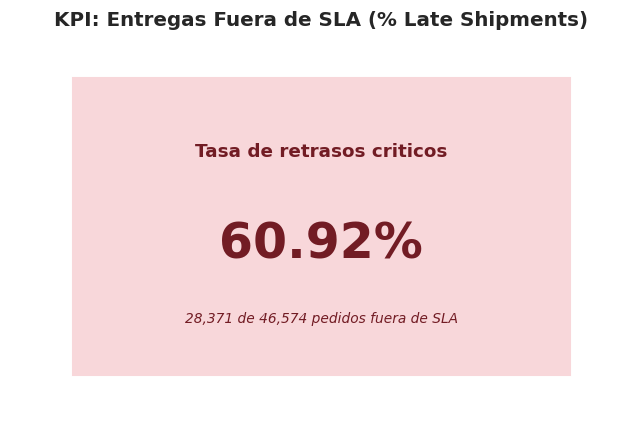

In [32]:
# Definir las condiciones del SLA oficial para cada modo de envío

#Deberia de ser por prioridad?
define_sla = {
    'Critical': 0,
    'High': 2,
    'Medium': 4,
    'Low': 6
}

# Mapear el SLA objetivo según el modo de envío
df['sla_target'] = df['order_priority'].map(define_sla)

# Un pedido está fuera de SLA si el process_time es estrictamente mayor que el sla_target
df['fuera_sla'] = df['diference'] > 0

# Calcular métricas
total_pedidos = len(df)
pedidos_fuera_sla = df['fuera_sla'].sum()
tasa_retraso_critico = (pedidos_fuera_sla / total_pedidos) * 100

print(f"Total de Pedidos: {total_pedidos:,}")
print(f"Pedidos Fuera de SLA: {pedidos_fuera_sla:,}")
print(f"Tasa de Retraso Crítico: {tasa_retraso_critico:.2f}%")

### Gráfico ###

# Crear visualización del KPI (Tarjeta Gráfica)
plt.figure(figsize=(6, 4))
plt.gca().add_patch(plt.Rectangle((0.1, 0.1), 0.8, 0.8, fill=True, color='#f8d7da', edgecolor='#f5c6cb', lw=2, transform=plt.gca().transAxes))

# Texto del KPI
plt.text(0.5, 0.7, "Tasa de retrasos criticos", ha='center', va='center', fontsize=12, fontweight='bold', color='#721c24')
plt.text(0.5, 0.45, f"{tasa_retraso_critico:.2f}%", ha='center', va='center', fontsize=32, fontweight='bold', color='#721c24')
plt.text(0.5, 0.25, f"{pedidos_fuera_sla:,} de {total_pedidos:,} pedidos fuera de SLA", ha='center', va='center', fontsize=9, color='#721c24', style='italic')

plt.axis('off')
plt.title('KPI: Entregas Fuera de SLA (% Late Shipments)', fontsize=13, pad=10, fontweight='bold')
plt.tight_layout()
plt.show()



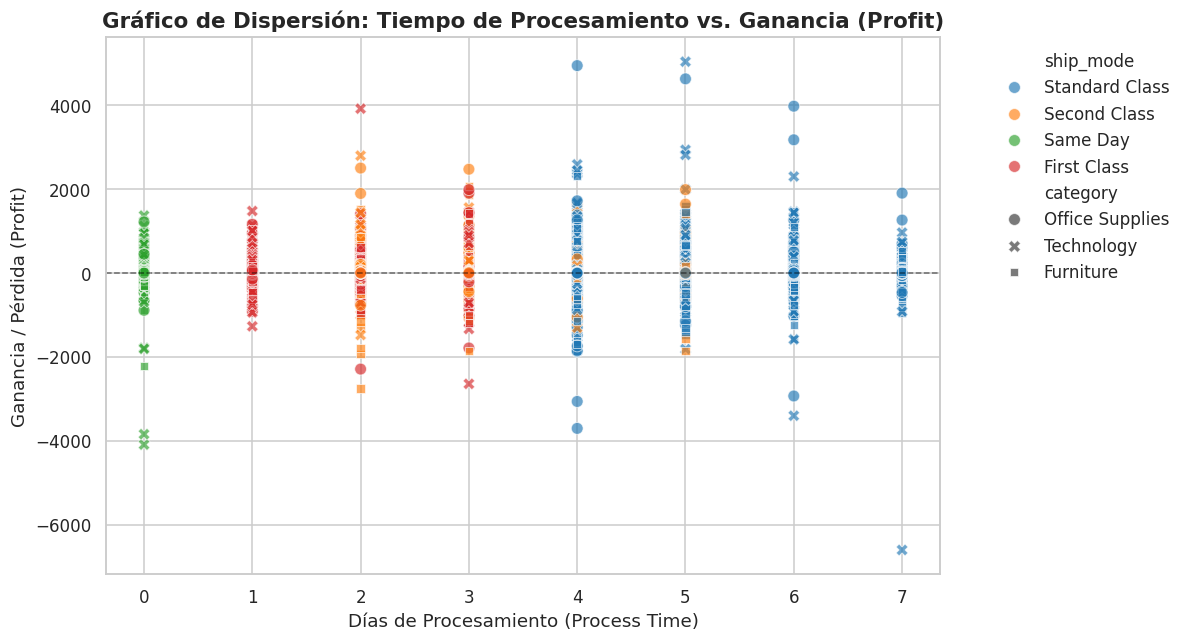

In [33]:
# Tiempo de Procesamiento (process_time) vs. Ganancia (profit)
# -----------------
#Creacion de la grafica
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x="process_time",
    y="profit",
    hue="ship_mode",
    style="category",
    palette="tab10",
    alpha=0.65,
    s=60,
)

#Configuracion de titulo y ejes
plt.title(
    "Gráfico de Dispersión: Tiempo de Procesamiento vs. Ganancia (Profit)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Días de Procesamiento (Process Time)", fontsize=12)
plt.ylabel("Ganancia / Pérdida (Profit)", fontsize=12)
plt.axhline(
    0, color="black", linestyle="--", linewidth=1, alpha=0.5
)  # Línea de equilibrio financiero
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

# Ense;ar grafico
plt.show()




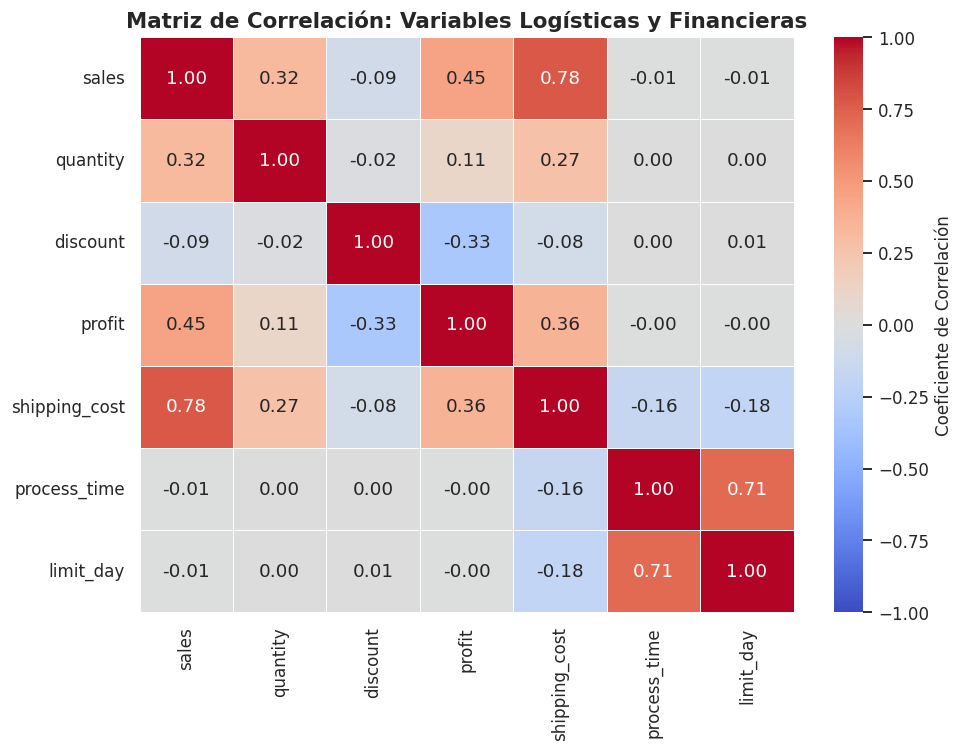

In [34]:
# Grafico 2: Matriz de Correlación
# Relación entre variables logísticas y financieras
# ----------------------------------------------------
plt.figure(figsize=(9, 7))

# Selección de variables numéricas relevantes
numeric_cols = [
    "sales",
    "quantity",
    "discount",
    "profit",
    "shipping_cost",
    "process_time",
    "limit_day",
]
df_corr = df[numeric_cols].copy()

# Cálculo de la matriz de correlación de Pearson
corr_matrix = df_corr.corr()

# Dibujar el mapa de calor (Heatmap)
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.6,
    cbar_kws={"label": "Coeficiente de Correlación"},
)

plt.title(
    "Matriz de Correlación: Variables Logísticas y Financieras",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()

# Ensenar
plt.show()


#**Fase 3**

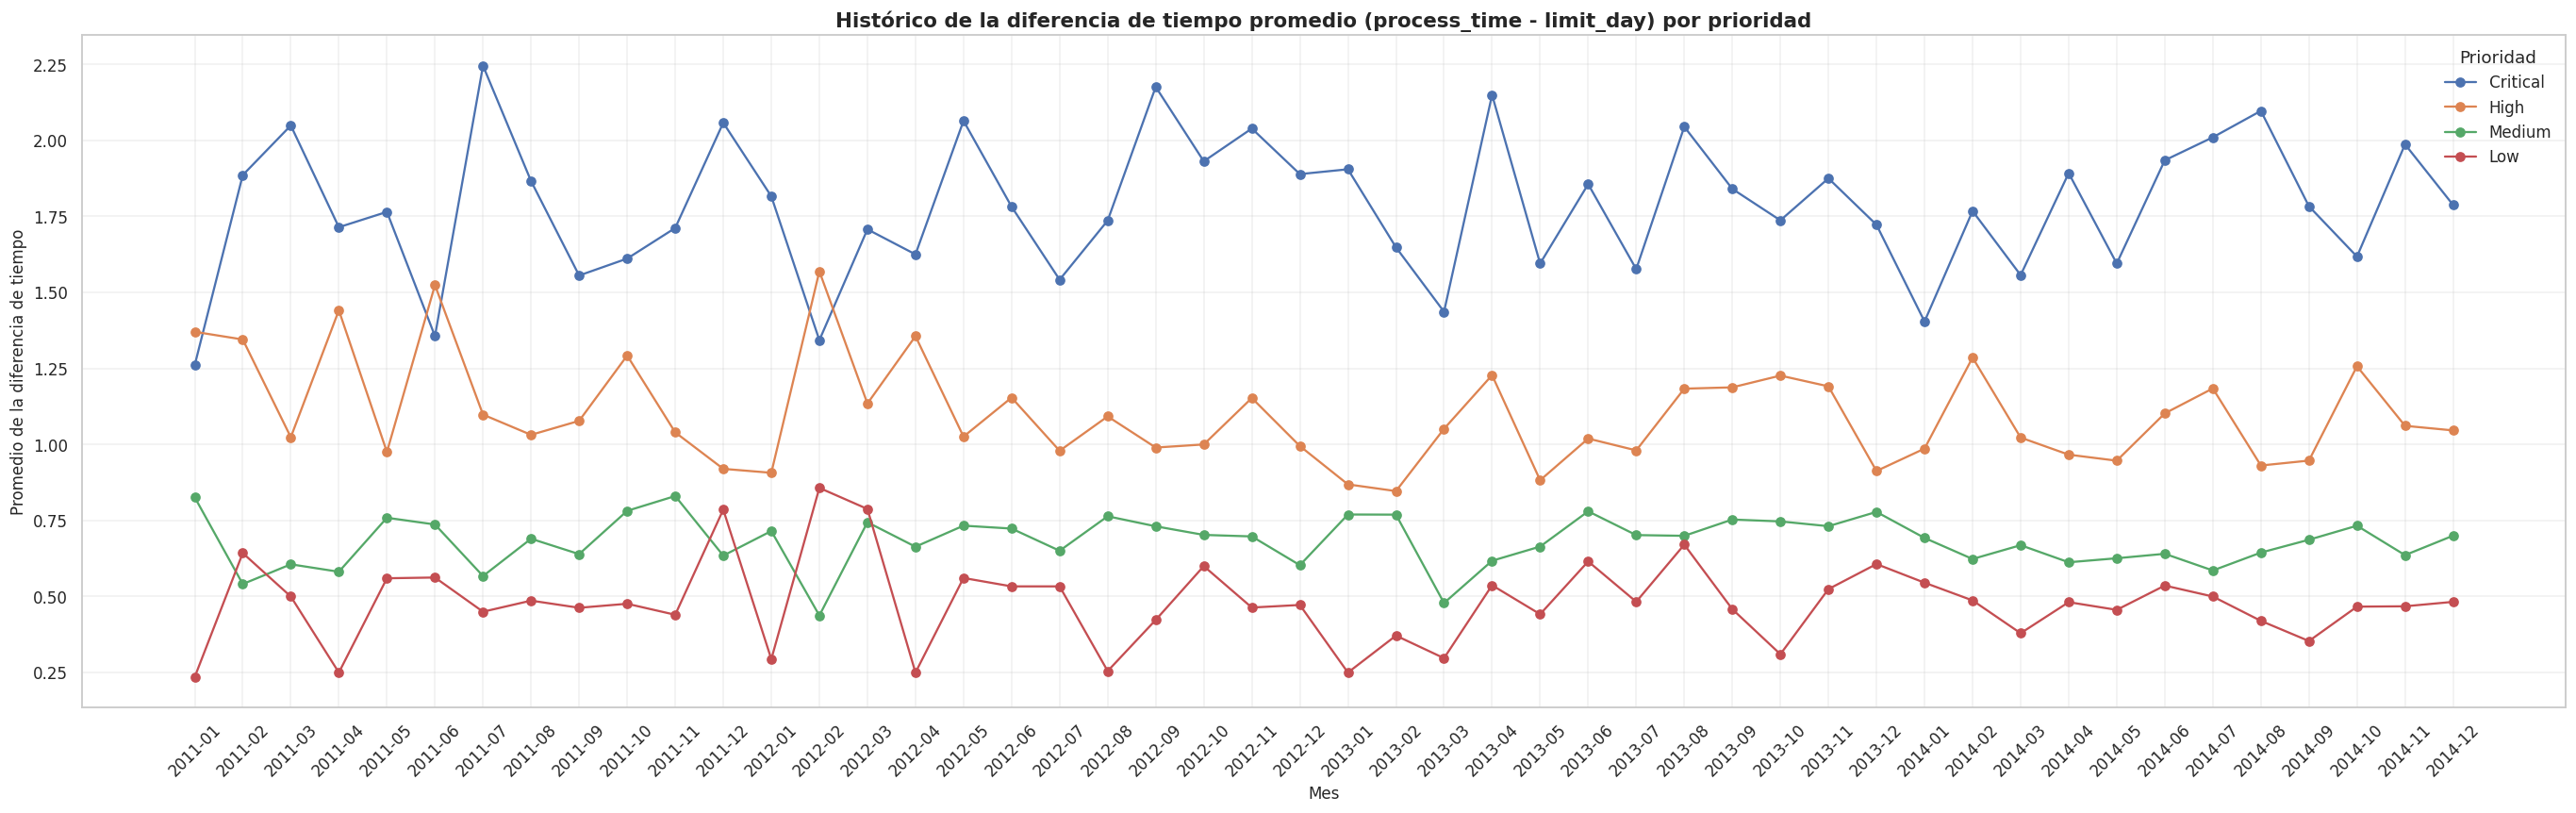

In [35]:
#low medium high critical process time - limit day

#Cambio de tipo de 'order_date' a tipo datetime especificando que el día va primero
df['order_date'] = pd.to_datetime(df['order_date'], dayfirst=True)

#Creacion de columnas adicionales para el agrupamiento y calculo del retraso de pedidos
df['month'] = df['order_date'].dt.to_period('M')
df['delay'] = df['process_time'] - df['limit_day']

#Agrupacion por el tipo de priodidad de la orden
grupos = df.groupby(['order_priority', 'month'])['delay'].mean()

#Segmentacion en grupos por aparte
critical = grupos.loc['Critical']
high = grupos.loc['High']
medium = grupos.loc['Medium']
low = grupos.loc['Low']

#Creacion de la grafica
grafica_historico, ax_historico = plt.subplots(figsize=(25, 8))

#Colocacion de los datos de cada grupo por la prioridad de la orden
ax_historico.plot(critical.index.astype(str), critical.values, marker='o', label='Critical')
ax_historico.plot(high.index.astype(str), high.values, marker='o', label='High')
ax_historico.plot(medium.index.astype(str), medium.values, marker='o', label='Medium')
ax_historico.plot(low.index.astype(str), low.values, marker='o', label='Low')

#Configuracion del titulo y ejes
ax_historico.set_title('Histórico de la diferencia de tiempo promedio (process_time - limit_day) por prioridad')
ax_historico.set_xlabel('Mes')
ax_historico.set_ylabel('Promedio de la diferencia de tiempo')
ax_historico.legend(title='Prioridad')
ax_historico.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

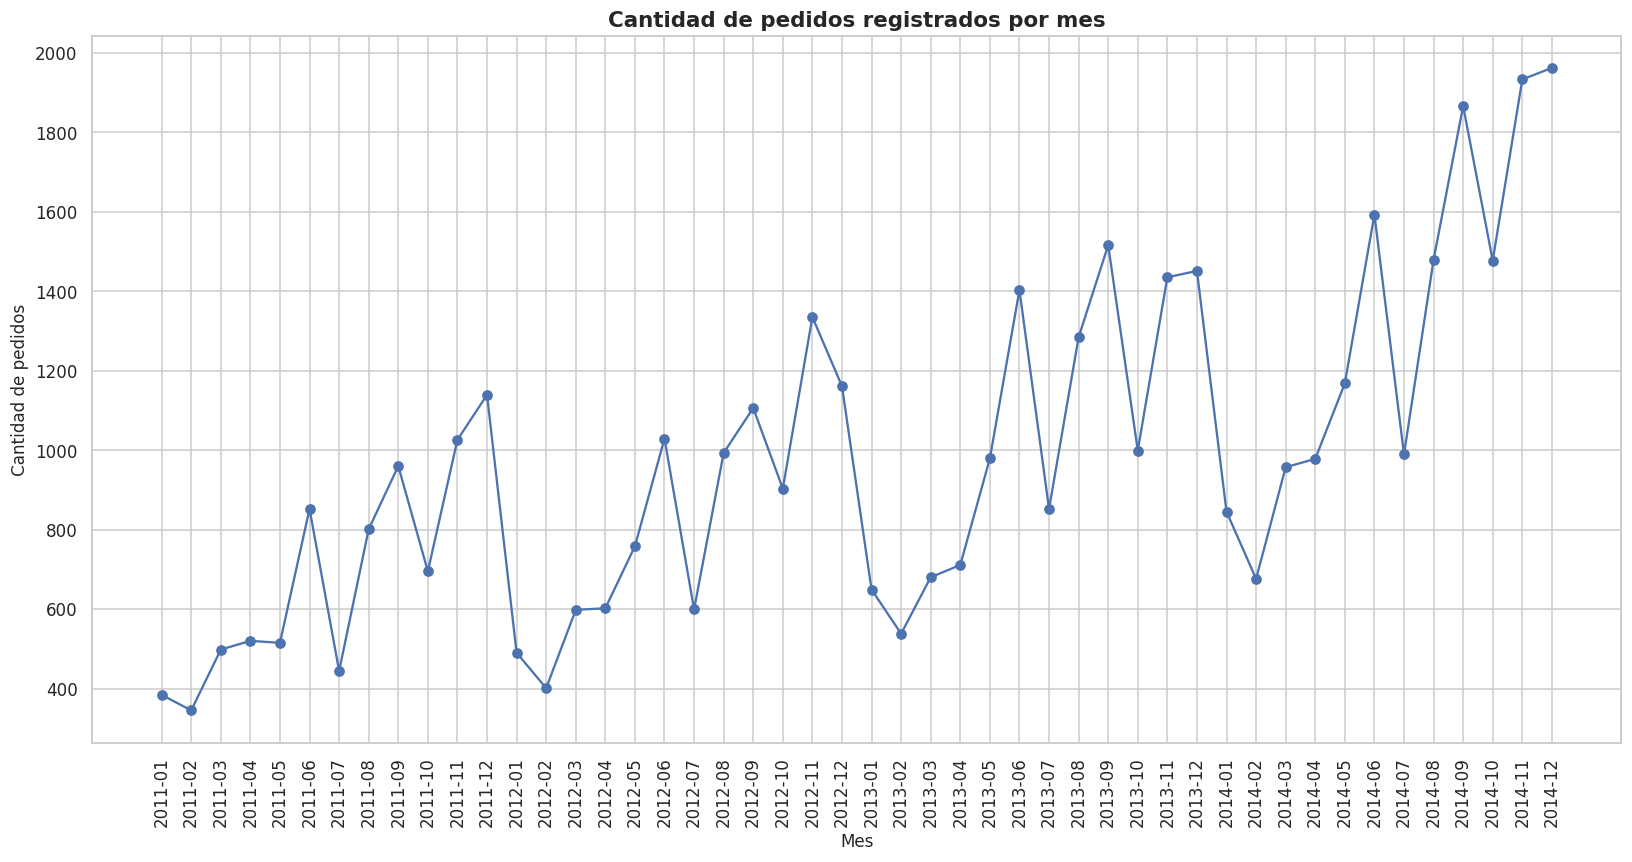


Fechas
Fecha inicial: 2011-01-01 00:00:00
Fecha final: 2014-12-31 00:00:00


In [36]:
#Agrupacion de los datos por mes junto a la cantidad de pedidos por mes
por_mes = df.groupby('month').size()

#Creacion de la grafica
grafica_volumen, ax_volumen = plt.subplots(figsize=(15,8))

#Colocacion de los datos obtenidos
ax_volumen.plot(
    por_mes.index.astype(str),
    por_mes.values,
    marker='o'
)

#Configuracion de titulo y ejes
ax_volumen.set_title('Cantidad de pedidos registrados por mes')
ax_volumen.set_xlabel('Mes')
ax_volumen.set_ylabel('Cantidad de pedidos')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print()
print('Fechas')
print("Fecha inicial:", df['order_date'].min())
print("Fecha final:", df['order_date'].max())

#**Fase 4**

# Identificar la "North Star Metric"
De lo que graficamos el identificar estrella es process_time, debido a que el resto de variables y el analisis va sugeto al process time


# Seleccionar los KPIs de soporte
KPI 1: Tiempo Promedio de Procesamiento, es decir Processing Time

KPI 2: Tasa de Cumplimiento de SLA es decir % On-Time Shipping

KPI 3: Tasa de Retraso Crítico (% Late Shipments)

KPI 4: Índice de Cuello de Botella Regional y por Categoría


# Grafica de dispersion para valores atipicos


# Carga de archivo

In [37]:
print("Sube tu archivo 'Base de datos atipicos - DERI Solutions.csv':")
uploaded = files.upload()
nombre_archivo = list(uploaded.keys())[0]
# Se añade encoding='latin1' para evitar el error de decodificación de caracteres especiales
df = pd.read_csv(io.BytesIO(uploaded[nombre_archivo]), encoding='latin1')

Sube tu archivo 'Base de datos atipicos - DERI Solutions.csv':


Saving datos_ordenes_atipicos.csv to datos_ordenes_atipicos (3).csv


# Grafica

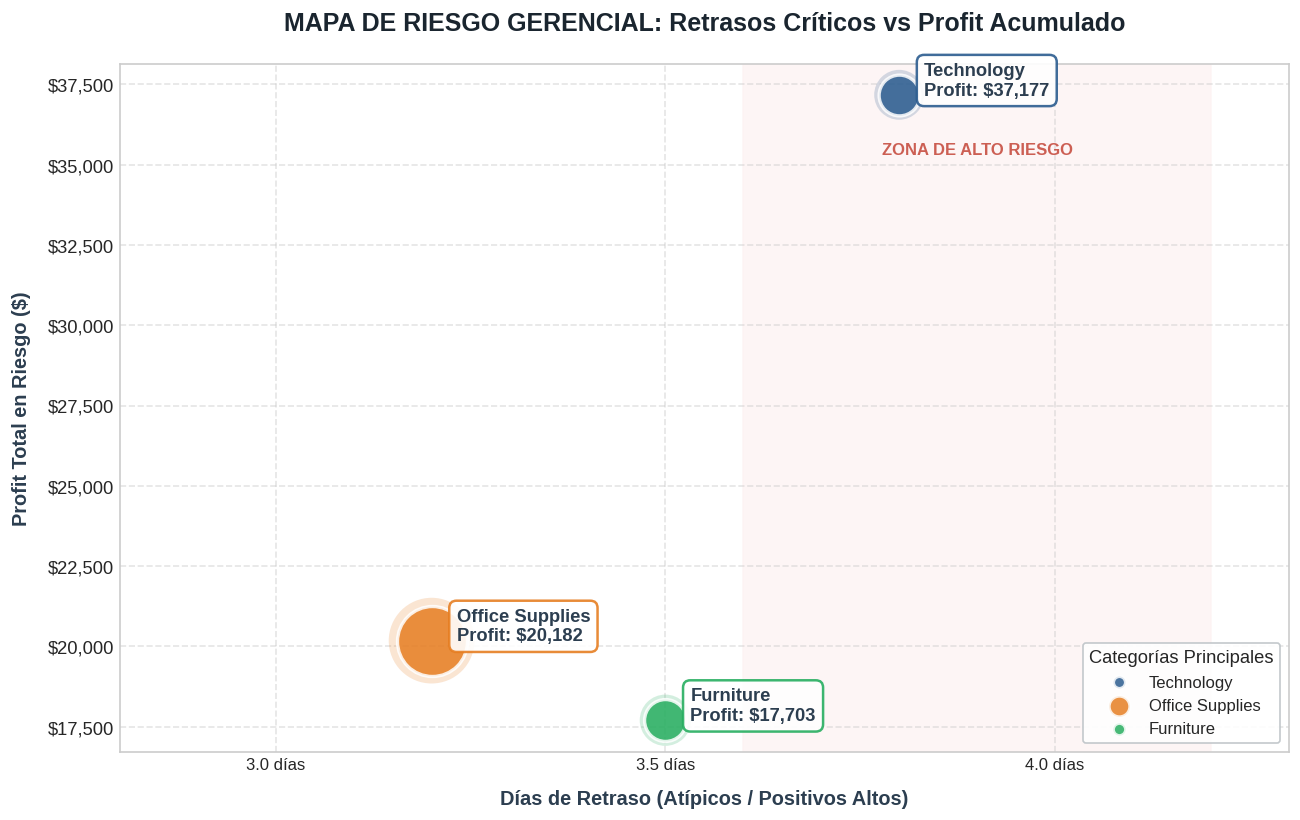

In [38]:
# 1. Botón interactivo para subir el archivo CSV Felipe

# 2. Calcular los días de retraso y filtrar únicamente los positivos altos
df["delay"] = df["process_time"] - df["limit_day"]
df_filtered = df[df["delay"] > 0]

# Agrupar y sumar los valores por cada categoría
df_grouped = (
    df_filtered.groupby("category")
    .agg({"profit": "sum", "quantity": "sum"})
    .reset_index()
)

# 3. Configurar estilo y paleta de colores moderna de alta calidad
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
fig, ax = plt.subplots(figsize=(11, 7), dpi=120)

colors = {
    "Technology": "#2b5c8f",  # Azul ejecutivo
    "Office Supplies": "#e67e22",  # Naranja ámbar
    "Furniture": "#27ae60",  # Verde esmeralda
}

data_plot = [
    {
        "cat": "Technology",
        "x": 3.8,
        "y": df_grouped.loc[
            df_grouped["category"] == "Technology", "profit"
        ].values[0],
        "size": df_grouped.loc[
            df_grouped["category"] == "Technology", "quantity"
        ].values[0]
        * 0.45,
        "color": colors["Technology"],
    },
    {
        "cat": "Office Supplies",
        "x": 3.2,
        "y": df_grouped.loc[
            df_grouped["category"] == "Office Supplies", "profit"
        ].values[0],
        "size": df_grouped.loc[
            df_grouped["category"] == "Office Supplies", "quantity"
        ].values[0]
        * 0.45,
        "color": colors["Office Supplies"],
    },
    {
        "cat": "Furniture",
        "x": 3.5,
        "y": df_grouped.loc[
            df_grouped["category"] == "Furniture", "profit"
        ].values[0],
        "size": df_grouped.loc[
            df_grouped["category"] == "Furniture", "quantity"
        ].values[0]
        * 0.45,
        "color": colors["Furniture"],
    },
]

# Fondo sutil para la zona crítica de alto riesgo
ax.axvspan(3.6, 4.2, color="#fdf2f2", alpha=0.7, zorder=0)
ax.text(
    3.9,
    max([d["y"] for d in data_plot]) * 0.95,
    "ZONA DE ALTO RIESGO",
    color="#c0392b",
    fontsize=10,
    fontweight="bold",
    ha="center",
    alpha=0.8,
)

# Dibujar las burbujas y sus etiquetas con diseño flotante
for d in data_plot:
    # Sombra difuminada de fondo
    ax.scatter(
        d["x"],
        d["y"],
        s=d["size"] * 1.5,
        color=d["color"],
        alpha=0.2,
        edgecolor="none",
        zorder=2,
    )
    # Burbuja principal
    ax.scatter(
        d["x"],
        d["y"],
        s=d["size"],
        color=d["color"],
        alpha=0.85,
        edgecolor="white",
        linewidth=2,
        zorder=3,
        label=d["cat"],
    )

    # Caja de texto flotante elegante
    ax.annotate(
        f"{d['cat']}\nProfit: ${d['y']:,.0f}",
        (d["x"], d["y"]),
        xytext=(15, 0),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="#2c3e50",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor=d["color"],
            alpha=0.9,
            linewidth=1.5,
        ),
        zorder=4,
    )

# 4. Personalización de ejes y formato ejecutivo
ax.set_title(
    "MAPA DE RIESGO GERENCIAL: Retrasos Críticos vs Profit Acumulado",
    fontsize=15,
    fontweight="bold",
    pad=20,
    color="#1a252f",
)
ax.set_xlabel(
    "Días de Retraso (Atípicos / Positivos Altos)",
    fontsize=12,
    fontweight="semibold",
    labelpad=10,
    color="#2c3e50",
)
ax.set_ylabel(
    "Profit Total en Riesgo ($)",
    fontsize=12,
    fontweight="semibold",
    labelpad=10,
    color="#2c3e50",
)

ax.set_xlim(2.8, 4.3)
ax.set_xticks([3.0, 3.5, 4.0])
ax.set_xticklabels(["3.0 días", "3.5 días", "4.0 días"], fontsize=10)

#
ax.yaxis.set_major_formatter("${x:,.0f}")

# Cuadrícula limpia
ax.grid(True, linestyle="--", alpha=0.5, zorder=1)

# Leyenda ejecutiva
ax.legend(
    title="Categorías Principales",
    title_fontsize="11",
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#bdc3c7",
    framealpha=0.9,
    fontsize=10,
    markerscale=0.3
)

plt.tight_layout()
plt.show()